In [ ]:
# Basic imports
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
model_files = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith(".keras") or file.endswith(".h5"):
            model_files.append(os.path.join(root, file))

print("Saved model files found:\n")
for f in model_files:
    print(f)


Saved model files found:

/content/drive/MyDrive/models/model_2_1.keras
/content/drive/MyDrive/Fruit_CNN_Models/phase1_baseline_cnn.keras
/content/drive/MyDrive/Fruit_CNN_Models/phase2_early_stopping.keras
/content/drive/MyDrive/Fruit_CNN_Models/phaseC1_cnn_augmented.keras
/content/drive/MyDrive/Fruit_CNN_Models/phaseC2_cnn_early_stop.keras
/content/drive/MyDrive/Fruit_CNN_Models/phaseD1_mobilenet_frozen.keras


In [ ]:
model_path = "/content/drive/MyDrive/Fruit_CNN_Models/phaseC2_cnn_early_stop.keras"

model = tf.keras.models.load_model(model_path)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,507,269 (127.82 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,338,180 (85.21 MB)

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [ ]:
!kaggle datasets list

ref                                                                    title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------------------------  --------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
saidaminsaidaxmadov/chocolate-sales                                    Chocolate Sales                                         468320  2026-01-04 14:23:35.490000              0         82  1.0              
neurocipher/heartdisease                                               Heart Disease                                             3491  2025-12-11 15:29:14.327000           2114        367  1.0              
rockyt07/social-media-user-analysis                                    Social Media User Analysis                           247842357  2026-01-14 02:28:41.970000           

In [ ]:
!kaggle datasets download -d sriramr/fruits-fresh-and-rotten-for-classification


Dataset URL: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification
License(s): unknown
100% 3.58G/3.58G [00:48<00:00, 241MB/s]
100% 3.58G/3.58G [00:48<00:00, 78.9MB/s]


In [ ]:
!unzip fruits-fresh-and-rotten-for-classification.zip -d /content/kaggle_fruits


Streaming output truncated to the last 5000 lines.
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.09 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.18 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.24 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.37 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.51 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.02 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.12 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.2

In [ ]:
import os

os.listdir("/content/kaggle_fruits")


['dataset']

In [ ]:
import os

os.listdir("/content/kaggle_fruits/dataset")


['dataset', 'test', 'train']

In [ ]:
os.listdir("/content/kaggle_fruits/dataset/test")


['freshbanana',
 'freshoranges',
 'rottenbanana',
 'rottenoranges',
 'rottenapples',
 'freshapples']

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_dir = "/content/kaggle_fruits/dataset/test"

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode=None,   # IMPORTANT
    shuffle=False
)


Found 2698 images belonging to 6 classes.


In [ ]:
import numpy as np

binary_labels = []

for path in test_generator.filepaths:
    folder = path.split("/")[-2].lower()

    if folder.startswith("fresh"):
        binary_labels.append(0)   # Fresh
    elif folder.startswith("rotten"):
        binary_labels.append(1)   # Rotten
    else:
        raise ValueError(f"Unknown class: {folder}")

y_true = np.array(binary_labels)


In [ ]:
y_prob = model.predict(test_generator, verbose=1)
y_pred = (y_prob >= 0.5).astype(int).flatten()


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


85/85 ━━━━━━━━━━━━━━━━━━━━ 17s 179ms/step


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1-score :", f1_score(y_true, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=["Fresh", "Rotten"]))


Accuracy : 0.6908821349147517
Precision: 0.9641909814323607
Recall   : 0.47392438070404175
F1-score : 0.6354895104895105

Classification Report:

              precision    recall  f1-score   support

       Fresh       0.58      0.98      0.73      1164
      Rotten       0.96      0.47      0.64      1534

    accuracy                           0.69      2698
   macro avg       0.77      0.73      0.68      2698
weighted avg       0.80      0.69      0.68      2698



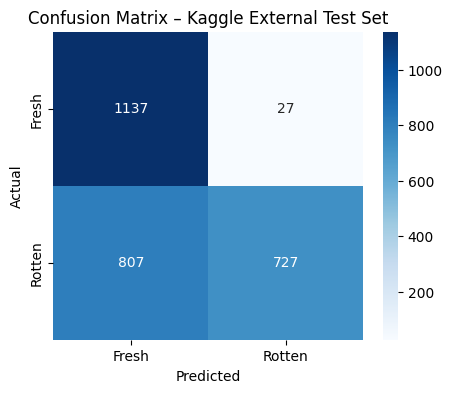

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fresh", "Rotten"],
    yticklabels=["Fresh", "Rotten"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Kaggle External Test Set")
plt.show()


In [ ]:
import numpy as np

img_path = "/content/drive/MyDrive/aiapple.jpg"

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0   # same preprocessing as training

pred = model.predict(img_arr)
print(pred)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
[[3.7055872e-10]]


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/apple-gone-bad.jpg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Raw sigmoid output: 0.34137896


In [ ]:
model.layers[-1].activation


<function keras.src.activations.activations.sigmoid(x)>

In [ ]:
flow_from_directory(
    class_mode='binary'
)


NameError: name 'flow_from_directory' is not defined

In [ ]:
train_generator.class_indices


NameError: name 'train_generator' is not defined

In [ ]:
test_generator.class_indices


{'freshapples': 0,
 'freshbanana': 1,
 'freshoranges': 2,
 'rottenapples': 3,
 'rottenbanana': 4,
 'rottenoranges': 5}

In [ ]:
import os

# Point this to the TRAIN directory you used originally
train_dir = "/content/drive/MyDrive/Final_Dataset/train"

classes = sorted(os.listdir(train_dir))
print(classes)


['Fresh', 'Rotten']


In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/apple-gone-bad.jpg"

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = preprocess_input(img_arr)  # ✅ CORRECT

pred = model.predict(img_arr)
print("Correct sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Correct sigmoid output: 0.9999968


In [ ]:
!kaggle datasets download -d riescoalieffe/fruitmate


Dataset URL: https://www.kaggle.com/datasets/riescoalieffe/fruitmate
License(s): unknown
  0% 0.00/12.6M [00:00<?, ?B/s]
100% 12.6M/12.6M [00:00<00:00, 1.08GB/s]


In [ ]:
!unzip fruitmate.zip -d /content/fruitmate


Archive:  fruitmate.zip
  inflating: /content/fruitmate/Testing/Overripe/Overripe004.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe006.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe007.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe008.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe011.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe012.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe021.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe022.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe023.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe027.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe028.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe029.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe036.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe038.jpeg  
  inflating: /content/fr

In [ ]:
os.listdir("/content/fruitmate")


['Training', 'Testing', 'Validation']

In [ ]:
import os

os.listdir("/content/fruitmate/Testing")


['Unripe', 'Overripe', 'Ripe']

In [ ]:
fruitmate_test_dir = "/content/fruitmate/Testing"


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    fruitmate_test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode=None,    # IMPORTANT
    shuffle=False
)


Found 57 images belonging to 3 classes.


In [ ]:
y_true = []
valid_indices = []

for idx, path in enumerate(test_generator.filepaths):
    folder = path.split("/")[-2].lower()

    if folder == "ripe":
        y_true.append(0)        # Fresh
        valid_indices.append(idx)

    elif folder == "overripe":
        y_true.append(1)        # Rotten
        valid_indices.append(idx)

    else:
        # unripe → excluded
        continue

y_true = np.array(y_true)

print("Total images in Testing:", len(test_generator.filepaths))
print("Used (Ripe + Overripe):", len(y_true))
print("Excluded (Unripe):", len(test_generator.filepaths) - len(y_true))


Total images in Testing: 57
Used (Ripe + Overripe): 38
Excluded (Unripe): 19


In [ ]:
model_path = "/content/drive/MyDrive/Fruit_CNN_Models/phase2_early_stopping.keras"

model = tf.keras.models.load_model(model_path)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,507,269 (127.82 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,338,180 (85.21 MB)

In [ ]:
# Predict on ALL FruitMate test images
y_prob_all = model.predict(test_generator, verbose=1)

# Keep only Ripe + Overripe samples
y_prob = y_prob_all[valid_indices]
y_pred = (y_prob >= 0.5).astype(int).flatten()


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 418ms/step


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1-score :", f1_score(y_true, y_pred))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fresh", "Rotten"]
))


Accuracy : 0.7368421052631579
Precision: 0.7647058823529411
Recall   : 0.6842105263157895
F1-score : 0.7222222222222222

Classification Report:

              precision    recall  f1-score   support

       Fresh       0.71      0.79      0.75        19
      Rotten       0.76      0.68      0.72        19

    accuracy                           0.74        38
   macro avg       0.74      0.74      0.74        38
weighted avg       0.74      0.74      0.74        38



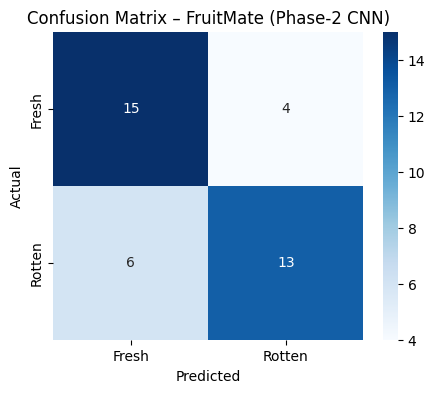

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fresh", "Rotten"],
    yticklabels=["Fresh", "Rotten"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – FruitMate (Phase-2 CNN)")
plt.show()


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [ ]:
mendeley_test_dir = "/content/drive/MyDrive/Final_Dataset/test"


In [ ]:
os.listdir(mendeley_test_dir)


['Fresh', 'Rotten']

In [ ]:
rescale = 1./255


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    mendeley_test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)


Found 848 images belonging to 2 classes.


In [ ]:
test_generator.class_indices


{'Fresh': 0, 'Rotten': 1}

In [ ]:
model_path = "/content/drive/MyDrive/Fruit_CNN_Models/phase2_early_stopping.keras"
model = tf.keras.models.load_model(model_path)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,507,269 (127.82 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,338,180 (85.21 MB)

In [ ]:
y_prob = model.predict(test_generator, verbose=1)
y_pred = (y_prob >= 0.5).astype(int).flatten()
y_true = test_generator.classes


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


27/27 ━━━━━━━━━━━━━━━━━━━━ 291s 11s/step


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1-score :", f1_score(y_true, y_pred))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fresh", "Rotten"]
))



Accuracy : 0.9846698113207547
Precision: 0.9794050343249427
Recall   : 0.9907407407407407
F1-score : 0.9850402761795167

Classification Report:

              precision    recall  f1-score   support

       Fresh       0.99      0.98      0.98       416
      Rotten       0.98      0.99      0.99       432

    accuracy                           0.98       848
   macro avg       0.98      0.98      0.98       848
weighted avg       0.98      0.98      0.98       848



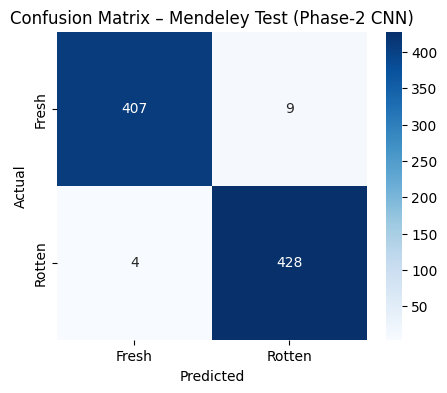

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fresh", "Rotten"],
    yticklabels=["Fresh", "Rotten"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Mendeley Test (Phase-2 CNN)")
plt.show()


In [ ]:
import os

test_dir = "/content/drive/MyDrive/Final_Dataset/test"

for cls in os.listdir(test_dir):
    cls_path = os.path.join(test_dir, cls)
    print(f"{cls}: {len(os.listdir(cls_path))} images")


Fresh: 416 images
Rotten: 432 images


In [ ]:
from collections import Counter

fruit_counter = Counter()

for cls in ["Fresh", "Rotten"]:
    cls_path = os.path.join(test_dir, cls)
    for fname in os.listdir(cls_path):
        # Example filename: FreshApple_123.jpg
        fruit = fname.split("_")[0].replace("Fresh", "").replace("Rotten", "")
        fruit_counter[fruit] += 1

print(fruit_counter)


Counter({'Guava': 111, 'Apple': 110, 'Banana': 106, 'Pomegranate': 106, 'Orange': 105, 'Jujube': 104, 'Grape': 103, 'Strawberry': 103})


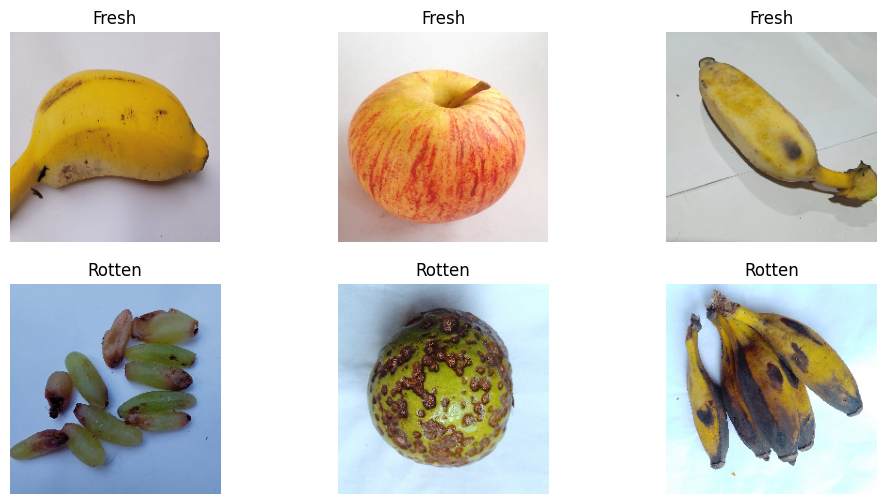

In [ ]:
import random
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img

def show_random_test_images(n=6):
    images = []
    labels = []

    for cls in ["Fresh", "Rotten"]:
        cls_path = os.path.join(test_dir, cls)
        files = random.sample(os.listdir(cls_path), n//2)
        for f in files:
            images.append(load_img(os.path.join(cls_path, f), target_size=(224,224)))
            labels.append(cls)

    plt.figure(figsize=(12,6))
    for i, img in enumerate(images):
        plt.subplot(2, n//2, i+1)
        plt.imshow(img)
        plt.title(labels[i])
        plt.axis("off")
    plt.show()

show_random_test_images()


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [ ]:
!kaggle datasets download -d nourabdoun/fruits-quality-fresh-vs-rotten


Dataset URL: https://www.kaggle.com/datasets/nourabdoun/fruits-quality-fresh-vs-rotten
License(s): other
fruits-quality-fresh-vs-rotten.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!find "/content/fruit_quality/Quality Dataset" -maxdepth 3 -type d


/content/fruit_quality/Quality Dataset
/content/fruit_quality/Quality Dataset/test
/content/fruit_quality/Quality Dataset/test/rotten
/content/fruit_quality/Quality Dataset/test/fresh
/content/fruit_quality/Quality Dataset/train
/content/fruit_quality/Quality Dataset/train/rotten
/content/fruit_quality/Quality Dataset/train/fresh
/content/fruit_quality/Quality Dataset/valid
/content/fruit_quality/Quality Dataset/valid/rotten
/content/fruit_quality/Quality Dataset/valid/fresh


In [ ]:
test_dir = "/content/fruit_quality/Quality Dataset/test"

for cls in os.listdir(test_dir):
    cls_path = os.path.join(test_dir, cls)
    print(cls, "->", len(os.listdir(cls_path)))


rotten -> 12
fresh -> 12


In [ ]:
!unzip fruits-quality-fresh-vs-rotten.zip -d /content/fruit_quality


Archive:  fruits-quality-fresh-vs-rotten.zip
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/download-15-_jpeg.rf.eb38a9d46791a8c19a85f6c64ed7397f.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/download-16-_jpeg.rf.c7b8abae08fbb0bc71ca918dec3e2f02.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/download-18-_jpeg.rf.d642f70a2a7ca8bf876121d8680fc035.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/images-13-_jpeg.rf.548d3de3cfbe2bd64344b7bface3db6c.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/images-16-_jpeg.rf.189d83ef79f529156ee193da575306cb.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/images-18-_jpeg.rf.2fbad83c8e6e13743cf7396d1844d60c.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/images-25-_jpeg.rf.c70cb6d11ea5330992536bf8f4a59a2f.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/images-4-_jpeg.rf.c5b3a62e15ff5293396dd

In [ ]:
os.listdir("/content/fruit_quality")


['Quality Dataset']

In [ ]:
os.listdir("/content/fruit_quality/Quality Dataset")


['test', 'train', 'valid']

In [ ]:
os.listdir("/content/fruit_quality/Quality Dataset/test")


['rotten', 'fresh']

In [ ]:
fruit_quality_test_dir = "/content/fruit_quality/Quality Dataset/test"


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    fruit_quality_test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)


Found 24 images belonging to 2 classes.


In [ ]:
test_generator.class_indices


{'fresh': 0, 'rotten': 1}

In [ ]:
model_path = "/content/drive/MyDrive/Fruit_CNN_Models/phase2_early_stopping.keras"
model = tf.keras.models.load_model(model_path)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,507,269 (127.82 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,338,180 (85.21 MB)

In [ ]:
y_prob = model.predict(test_generator, verbose=1)
y_pred = (y_prob >= 0.5).astype(int).flatten()
y_true = test_generator.classes


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1-score :", f1_score(y_true, y_pred))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fresh", "Rotten"]
))


Accuracy : 0.625
Precision: 0.6153846153846154
Recall   : 0.6666666666666666
F1-score : 0.64

Classification Report:

              precision    recall  f1-score   support

       Fresh       0.64      0.58      0.61        12
      Rotten       0.62      0.67      0.64        12

    accuracy                           0.62        24
   macro avg       0.63      0.62      0.62        24
weighted avg       0.63      0.62      0.62        24



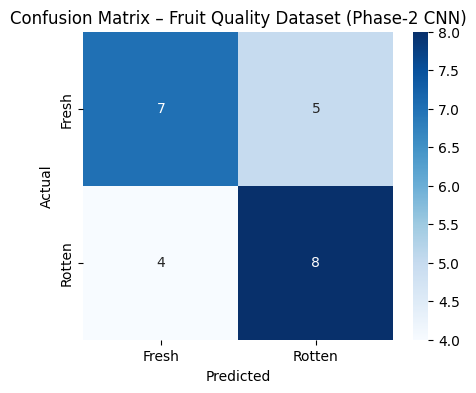

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fresh", "Rotten"],
    yticklabels=["Fresh", "Rotten"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Fruit Quality Dataset (Phase-2 CNN)")
plt.show()


In [ ]:
!kaggle datasets download -d nourabdoun/fruits-quality-fresh-vs-rotten


Dataset URL: https://www.kaggle.com/datasets/nourabdoun/fruits-quality-fresh-vs-rotten
License(s): other
  0% 0.00/11.2M [00:00<?, ?B/s]
100% 11.2M/11.2M [00:00<00:00, 1.83GB/s]


In [ ]:
!unzip fruits-quality-fresh-vs-rotten.zip -d /content/fruit_quality


Archive:  fruits-quality-fresh-vs-rotten.zip
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/download-15-_jpeg.rf.eb38a9d46791a8c19a85f6c64ed7397f.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/download-16-_jpeg.rf.c7b8abae08fbb0bc71ca918dec3e2f02.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/download-18-_jpeg.rf.d642f70a2a7ca8bf876121d8680fc035.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/images-13-_jpeg.rf.548d3de3cfbe2bd64344b7bface3db6c.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/images-16-_jpeg.rf.189d83ef79f529156ee193da575306cb.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/images-18-_jpeg.rf.2fbad83c8e6e13743cf7396d1844d60c.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/images-25-_jpeg.rf.c70cb6d11ea5330992536bf8f4a59a2f.jpg  
  inflating: /content/fruit_quality/Quality Dataset/test/fresh/images-4-_jpeg.rf.c5b3a62e15ff5293396dd

In [ ]:
# Count test images again
test_dir = "/content/fruit_quality/Quality Dataset/test"
total = 0
for cls in os.listdir(test_dir):
    cls_path = os.path.join(test_dir, cls)
    n = len(os.listdir(cls_path))
    total += n
    print(f"{cls} -> {n} images")

print(f"\nTotal test images: {total}")


rotten -> 12 images
fresh -> 12 images

Total test images: 24


In [ ]:
import os

os.listdir("/content/fruit_quality")


['Quality Dataset']

In [ ]:
os.listdir("/content/fruit_quality/Quality Dataset")


['test', 'train', 'valid']

In [ ]:
test_dir = "/content/fruit_quality/Quality Dataset/test"
os.listdir(test_dir)


['rotten', 'fresh']

In [ ]:
total = 0
for cls in os.listdir(test_dir):
    cls_path = os.path.join(test_dir, cls)
    n = len(os.listdir(cls_path))
    total += n
    print(f"{cls} -> {n} images")

print(f"\nTotal test images: {total}")


rotten -> 12 images
fresh -> 12 images

Total test images: 24


In [ ]:
rescale = 1./255


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)


Found 24 images belonging to 2 classes.


In [ ]:
import tensorflow as tf

model_path = "/content/drive/MyDrive/Fruit_CNN_Models/phase2_early_stopping.keras"
model = tf.keras.models.load_model(model_path)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,507,269 (127.82 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,338,180 (85.21 MB)

In [ ]:
import numpy as np

y_prob = model.predict(test_generator, verbose=1)
y_pred = (y_prob >= 0.5).astype(int).flatten()
y_true = test_generator.classes


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1-score :", f1_score(y_true, y_pred))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fresh", "Rotten"]
))


Accuracy : 0.625
Precision: 0.6153846153846154
Recall   : 0.6666666666666666
F1-score : 0.64

Classification Report:

              precision    recall  f1-score   support

       Fresh       0.64      0.58      0.61        12
      Rotten       0.62      0.67      0.64        12

    accuracy                           0.62        24
   macro avg       0.63      0.62      0.62        24
weighted avg       0.63      0.62      0.62        24



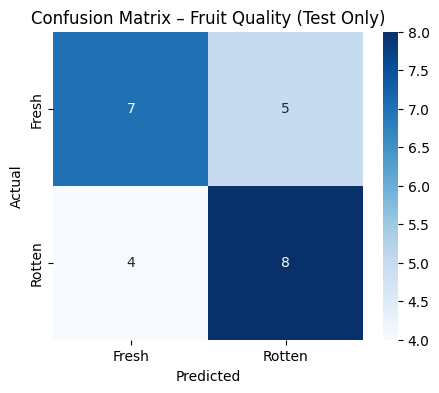

In [ ]:


import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fresh", "Rotten"],
    yticklabels=["Fresh", "Rotten"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Fruit Quality (Test Only)")
plt.show()


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!kaggle datasets download -d amitsubhashagrahari/fresh-or-rotten-fruit


Dataset URL: https://www.kaggle.com/datasets/amitsubhashagrahari/fresh-or-rotten-fruit
License(s): apache-2.0
  0% 0.00/1.75M [00:00<?, ?B/s]
100% 1.75M/1.75M [00:00<00:00, 213MB/s]


In [ ]:
!unzip fresh-or-rotten-fruit.zip -d /content/fresh_rotten_external


Archive:  fresh-or-rotten-fruit.zip
  inflating: /content/fresh_rotten_external/Dataset_1/1.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/10.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/100.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/101.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/102.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/103.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/104.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/105.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/106.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/107.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/108.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/109.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/11.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/110.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/111.

In [ ]:
os.listdir("/content/fresh_rotten_external")


['Dataset_1']

In [ ]:
os.listdir("/content/fresh_rotten_external/Dataset_1")


['73.jpeg',
 '200.jpeg',
 '118.jpeg',
 '31.jpeg',
 '42.jpeg',
 '225.jpeg',
 '198.jpeg',
 '203.jpeg',
 '124.jpeg',
 '60.jpeg',
 '90.jpeg',
 '133.jpeg',
 '201.jpeg',
 '178.jpeg',
 '163.jpeg',
 '150.jpeg',
 '161.jpeg',
 '132.jpeg',
 '17.jpeg',
 '72.jpeg',
 '8.jpeg',
 '175.jpeg',
 '7.jpeg',
 '110.jpeg',
 '142.jpeg',
 '68.jpeg',
 '125.jpeg',
 '119.jpeg',
 '156.jpeg',
 '85.jpeg',
 '99.jpeg',
 '103.jpeg',
 '226.jpeg',
 '220.jpeg',
 '43.jpeg',
 '158.jpeg',
 '22.jpeg',
 '180.jpeg',
 '202.jpeg',
 '215.jpeg',
 '25.jpeg',
 '36.jpeg',
 '126.jpeg',
 '216.jpeg',
 '96.jpeg',
 '209.jpeg',
 '49.jpeg',
 '105.jpeg',
 '37.jpeg',
 '141.jpeg',
 '165.jpeg',
 '4.jpeg',
 '207.jpeg',
 '169.jpeg',
 '136.jpeg',
 '151.jpeg',
 '205.jpeg',
 '3.jpeg',
 '147.jpeg',
 '190.jpeg',
 '170.jpeg',
 '153.jpeg',
 '214.jpeg',
 '159.jpeg',
 '2.jpeg',
 '64.jpeg',
 '93.jpeg',
 '87.jpeg',
 '14.jpeg',
 '89.jpeg',
 '160.jpeg',
 '197.jpeg',
 '104.jpeg',
 '95.jpeg',
 '55.jpeg',
 '134.jpeg',
 '191.jpeg',
 '217.jpeg',
 '35.jpeg',
 '194.jp

In [ ]:
os.listdir("/content/fresh_rotten_external")


['Dataset_1']

In [ ]:
os.listdir("/content/fresh_rotten_external/Dataset_1")


['73.jpeg',
 '200.jpeg',
 '118.jpeg',
 '31.jpeg',
 '42.jpeg',
 '225.jpeg',
 '198.jpeg',
 '203.jpeg',
 '124.jpeg',
 '60.jpeg',
 '90.jpeg',
 '133.jpeg',
 '201.jpeg',
 '178.jpeg',
 '163.jpeg',
 '150.jpeg',
 '161.jpeg',
 '132.jpeg',
 '17.jpeg',
 '72.jpeg',
 '8.jpeg',
 '175.jpeg',
 '7.jpeg',
 '110.jpeg',
 '142.jpeg',
 '68.jpeg',
 '125.jpeg',
 '119.jpeg',
 '156.jpeg',
 '85.jpeg',
 '99.jpeg',
 '103.jpeg',
 '226.jpeg',
 '220.jpeg',
 '43.jpeg',
 '158.jpeg',
 '22.jpeg',
 '180.jpeg',
 '202.jpeg',
 '215.jpeg',
 '25.jpeg',
 '36.jpeg',
 '126.jpeg',
 '216.jpeg',
 '96.jpeg',
 '209.jpeg',
 '49.jpeg',
 '105.jpeg',
 '37.jpeg',
 '141.jpeg',
 '165.jpeg',
 '4.jpeg',
 '207.jpeg',
 '169.jpeg',
 '136.jpeg',
 '151.jpeg',
 '205.jpeg',
 '3.jpeg',
 '147.jpeg',
 '190.jpeg',
 '170.jpeg',
 '153.jpeg',
 '214.jpeg',
 '159.jpeg',
 '2.jpeg',
 '64.jpeg',
 '93.jpeg',
 '87.jpeg',
 '14.jpeg',
 '89.jpeg',
 '160.jpeg',
 '197.jpeg',
 '104.jpeg',
 '95.jpeg',
 '55.jpeg',
 '134.jpeg',
 '191.jpeg',
 '217.jpeg',
 '35.jpeg',
 '194.jp

In [ ]:
[file for file in os.listdir("/content/fresh_rotten_external") if file.endswith(".csv")]


[]

In [ ]:
os.listdir("/content/fresh_rotten_external")


['Dataset_1']

In [ ]:
os.listdir("/content/fresh_rotten_external/Dataset_1")[:20]


['73.jpeg',
 '200.jpeg',
 '118.jpeg',
 '31.jpeg',
 '42.jpeg',
 '225.jpeg',
 '198.jpeg',
 '203.jpeg',
 '124.jpeg',
 '60.jpeg',
 '90.jpeg',
 '133.jpeg',
 '201.jpeg',
 '178.jpeg',
 '163.jpeg',
 '150.jpeg',
 '161.jpeg',
 '132.jpeg',
 '17.jpeg',
 '72.jpeg']

In [ ]:
[file for file in os.listdir("/content/fresh_rotten_external") if file.endswith(".csv")]


[]

In [ ]:
dataset_dir = "/content/fresh_rotten_external/Dataset_1"

all_images = [f for f in os.listdir(dataset_dir) if f.lower().endswith(".jpeg")]
print("Total images in dataset:", len(all_images))


Total images in dataset: 229


In [ ]:
dataset_dir = "/content/fresh_rotten_external/Dataset_1"

all_images = [f for f in os.listdir(dataset_dir) if f.lower().endswith(".jpeg")]
print("Total images in dataset:", len(all_images))


Total images in dataset: 229


In [ ]:
import os

dataset_dir = "/content/fresh_rotten_external/Dataset_1"

image_paths = [
    os.path.join(dataset_dir, f)
    for f in os.listdir(dataset_dir)
    if f.lower().endswith(".jpeg")
]

print("Total images in qualitative dataset:", len(image_paths))


Total images in qualitative dataset: 229


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

def predict_image(img_path, model):
    img = image.load_img(img_path, target_size=(224, 224))
    img_arr = image.img_to_array(img) / 255.0
    img_arr = np.expand_dims(img_arr, axis=0)

    prob = model.predict(img_arr, verbose=0)[0][0]

    label = "Rotten" if prob >= 0.5 else "Fresh"
    confidence = prob if label == "Rotten" else 1 - prob

    return label, confidence


In [ ]:
results = []

for img_path in image_paths:
    label, conf = predict_image(img_path, model)
    results.append({
        "image": os.path.basename(img_path),
        "predicted_label": label,
        "confidence": conf
    })


In [ ]:
import pandas as pd

df_results = pd.DataFrame(results)
df_results


,image,predicted_label,confidence
0,73.jpeg,Rotten,0.500605
1,200.jpeg,Rotten,0.919997
2,118.jpeg,Rotten,0.605225
3,31.jpeg,Fresh,0.999986
4,42.jpeg,Fresh,0.999715
...,...,...,...
224,182.jpeg,Fresh,0.999975
225,177.jpeg,Rotten,1.000000
226,75.jpeg,Fresh,0.999959
227,116.jpeg,Rotten,0.742438


In [ ]:
df_results["predicted_label"].value_counts()


,count
predicted_label,
Fresh,137
Rotten,92


In [ ]:
df_results.groupby("predicted_label")["confidence"].describe()


,count,mean,std,min,25%,50%,75%,max
predicted_label,,,,,,,,
Fresh,137.0,0.983500,0.066541,0.518710,0.999745,1.000000,1.000000,1.0
Rotten,92.0,0.940337,0.125867,0.500605,0.967780,0.998872,0.999993,1.0


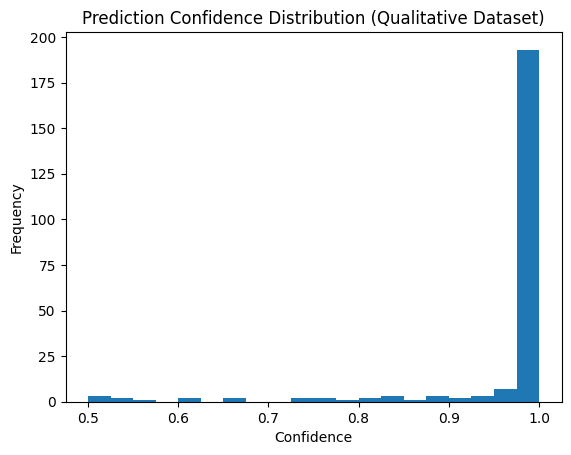

In [ ]:
import matplotlib.pyplot as plt

plt.hist(df_results["confidence"], bins=20)
plt.title("Prediction Confidence Distribution (Qualitative Dataset)")
plt.xlabel("Confidence")
plt.ylabel("Frequency")
plt.show()


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/apple-gone-bad.jpg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
Raw sigmoid output: 1.4955345e-05


In [ ]:
import os

os.listdir("/content/drive/MyDrive")


['Colab Notebooks',
 'IMG-20240708-WA0001.jpg',
 'Classroom',
 'PRACT 4.docx',
 'Screenshot (8).png',
 'impact-of-internet-of-things-on-society-IJERTCONV5IS03020.pdf',
 'IMG-20241010-WA0035.jpg',
 'rakshit_ladda.pdf',
 'SAMEEKSHA-IOT (2).pptx',
 'SAMEEKSHA-IOT (1).pptx',
 'SAMEEKSHA-IOT.pptx',
 'Copy of ELECTRICALAPPROVAL.gdoc',
 'Screenshot 2024-11-08 113926.png',
 'eee assingment.pdf',
 'Document from Rakshit Ladda.pdf',
 'BT24ECE063. RAKSHIT LADDA.pdf',
 'SAMKEESHA IOT funal paper.pdf',
 'Screenshot_2025-01-19-21-04-30-312_com.phonepe.app.jpg',
 'Screenshot_2025-01-25-10-17-57-042_com.miui.gallery.jpg',
 'Screenshot_2025-04-19-16-14-39-959_com.phonepe.app.jpg',
 'Untitled spreadsheet.gsheet',
 'RAKSHIT_LADDA(BT24CSD066).png',
 'BT24CSD066(RAKSHIT LADDA).png',
 'RAKSHIT LADDA(BT24CSD066) LOGO.jpg',
 ' BRANCH_CHANGE_APPLICATION.gdoc',
 'BT24CSD066(RAKSHIT LADDA)MINDEASE.pdf',
 'Screenshot 2025-09-05 121312.png',
 'TF_2025_BROCHURE EVE1.pdf',
 '50_Startups (1).csv.gsheet',
 '50_Startup

In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/WhatsApp Image 2026-01-23 at 19.48.56.jpeg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
Raw sigmoid output: 2.2192024e-05


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/WhatsApp Image 2026-01-23 at 19.48.55.jpeg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
Raw sigmoid output: 3.1409922e-07


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/WhatsApp Image 2026-01-23 at 19.48.56 (1).jpeg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Raw sigmoid output: 2.199345e-09


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns


Mounted at /content/drive


In [ ]:
import os

os.listdir("/content/drive/MyDrive")


['Colab Notebooks',
 'IMG-20240708-WA0001.jpg',
 'Classroom',
 'PRACT 4.docx',
 'Screenshot (8).png',
 'impact-of-internet-of-things-on-society-IJERTCONV5IS03020.pdf',
 'IMG-20241010-WA0035.jpg',
 'rakshit_ladda.pdf',
 'SAMEEKSHA-IOT (2).pptx',
 'SAMEEKSHA-IOT (1).pptx',
 'SAMEEKSHA-IOT.pptx',
 'Copy of ELECTRICALAPPROVAL.gdoc',
 'Screenshot 2024-11-08 113926.png',
 'eee assingment.pdf',
 'Document from Rakshit Ladda.pdf',
 'BT24ECE063. RAKSHIT LADDA.pdf',
 'SAMKEESHA IOT funal paper.pdf',
 'Screenshot_2025-01-19-21-04-30-312_com.phonepe.app.jpg',
 'Screenshot_2025-01-25-10-17-57-042_com.miui.gallery.jpg',
 'Screenshot_2025-04-19-16-14-39-959_com.phonepe.app.jpg',
 'Untitled spreadsheet.gsheet',
 'Screenshot 2025-06-08 211316.png',
 'RAKSHIT_LADDA(BT24CSD066).png',
 'BT24CSD066(RAKSHIT LADDA).png',
 'RAKSHIT LADDA(BT24CSD066) LOGO.jpg',
 ' BRANCH_CHANGE_APPLICATION.gdoc',
 'BT24CSD066(RAKSHIT LADDA)MINDEASE.pdf',
 'Screenshot 2025-09-05 121312.png',
 'TF_2025_BROCHURE EVE1.pdf',
 '50_S

In [ ]:
!unzip "/content/drive/MyDrive/Original Image -2.zip" -d "/content/fruitvision_raw"


Streaming output truncated to the last 5000 lines.
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63714.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63715.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63716.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63717.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63718.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63719.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63720.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63721.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63722.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63723.jpg  
  inflating: /content/fruitvi

In [ ]:
import os

os.listdir("/content/fruitvision_raw")


['Fruits Original']

In [ ]:
SOURCE_DIR = "/content/fruitvision_raw/Fruits Original"
TARGET_DIR = "/content/fruitvision_test_clean"


In [ ]:
import os
import shutil

if os.path.exists(TARGET_DIR):
    shutil.rmtree(TARGET_DIR)

os.makedirs(os.path.join(TARGET_DIR, "Fresh"), exist_ok=True)
os.makedirs(os.path.join(TARGET_DIR, "Rotten"), exist_ok=True)


In [ ]:
for folder in os.listdir(SOURCE_DIR):
    folder_path = os.path.join(SOURCE_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    folder_lower = folder.lower()

    if folder_lower.startswith("fresh"):
        target_class = "Fresh"
    elif folder_lower.startswith("rotten"):
        target_class = "Rotten"
    else:
        # This skips all Formalin-mixed folders
        continue

    for img in os.listdir(folder_path):
        shutil.copy(
            os.path.join(folder_path, img),
            os.path.join(TARGET_DIR, target_class, img)
        )


In [ ]:
import os, shutil

TARGET_DIR = "/content/fruitvision_test_clean"

if os.path.exists(TARGET_DIR):
    shutil.rmtree(TARGET_DIR)

os.makedirs(os.path.join(TARGET_DIR, "Fresh"), exist_ok=True)
os.makedirs(os.path.join(TARGET_DIR, "Rotten"), exist_ok=True)


In [ ]:
SOURCE_DIR = "/content/fruitvision_raw/Fruits Original"

image_extensions = (".jpg", ".jpeg", ".png")

fresh_count = 0
rotten_count = 0

for root, dirs, files in os.walk(SOURCE_DIR):
    folder_name = os.path.basename(root).lower()

    if "formalin" in folder_name:
        continue

    if "fresh" in folder_name:
        target_class = "Fresh"
    elif "rotten" in folder_name:
        target_class = "Rotten"
    else:
        continue

    for file in files:
        if file.lower().endswith(image_extensions):
            src = os.path.join(root, file)
            dst = os.path.join(TARGET_DIR, target_class, file)
            shutil.copy(src, dst)

            if target_class == "Fresh":
                fresh_count += 1
            else:
                rotten_count += 1


In [ ]:
print("Fresh images copied :", fresh_count)
print("Rotten images copied:", rotten_count)


Fresh images copied : 3800
Rotten images copied: 3178


In [ ]:
os.listdir("/content/fruitvision_test_clean/Fresh")[:5]
os.listdir("/content/fruitvision_test_clean/Rotten")[:5]


['msg5170347760-69099.jpg',
 '6158706318047820635.jpg',
 'msg5170347760-69155.jpg',
 'msg5170347760-68800.jpg',
 'msg5170347760-64827.jpg']

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "/content/fruitvision_test_clean",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

print("Class indices:", test_generator.class_indices)


Found 6918 images belonging to 2 classes.
Class indices: {'Fresh': 0, 'Rotten': 1}


In [ ]:
import tensorflow as tf

model_path = "/content/drive/MyDrive/Fruit_CNN_Models/phase2_early_stopping.keras"
model = tf.keras.models.load_model(model_path)


In [ ]:
y_prob = model.predict(test_generator, verbose=1)
y_pred = (y_prob >= 0.5).astype(int).flatten()
y_true = test_generator.classes


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


217/217 ━━━━━━━━━━━━━━━━━━━━ 356s 2s/step


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_true,
    y_pred,
    target_names=["Fresh", "Rotten"]
))


              precision    recall  f1-score   support

       Fresh       0.89      0.52      0.65      3740
      Rotten       0.62      0.93      0.74      3178

    accuracy                           0.71      6918
   macro avg       0.76      0.72      0.70      6918
weighted avg       0.77      0.71      0.70      6918



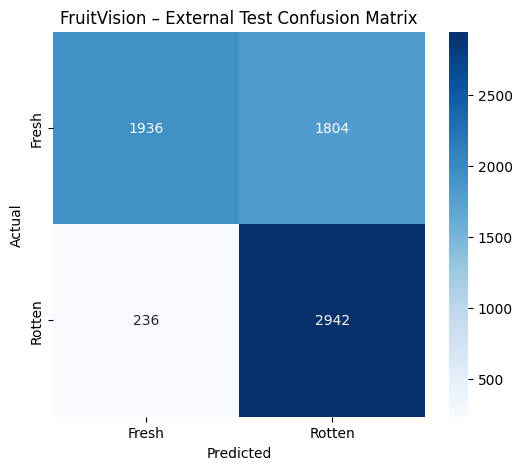

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fresh", "Rotten"],
            yticklabels=["Fresh", "Rotten"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("FruitVision – External Test Confusion Matrix")
plt.show()
